In [16]:
# Gerekli kütüphanelerin içe aktarılması
# NumPy: sayısal işlemler
# Matplotlib: grafik çizimi
# PyTorch: derin öğrenme modeli geliştirme
# Torchvision: MNIST veri setini yükleme ve dönüştürme işlemleri

import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim

from torchvision import datasets, transforms
from torch.utils.data import DataLoader, random_split

In [17]:
# Kullanılacak cihazın belirlenmesi
# Eğer GPU varsa CUDA kullanılacak, aksi halde CPU kullanılacak
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Kullanılan cihaz:", device)

Kullanılan cihaz: cuda


In [18]:
# PyTorch sürümünün ve CUDA desteğinin kontrol edilmesi
print("PyTorch Sürümü:", torch.__version__)
print("CUDA Kullanılabilir mi?:", torch.cuda.is_available())

PyTorch Sürümü: 2.11.0+cu130
CUDA Kullanılabilir mi?: True


In [19]:
# Sonuçların tekrar üretilebilir olması için rastgelelik tohumunun ayarlanması

torch.manual_seed(42)
np.random.seed(42)

if torch.cuda.is_available():
    torch.cuda.manual_seed(42)

print("Seed ayarlandı.")

Seed ayarlandı.


# 2. Veri Setinin Hazırlanması

## Bu bölümde MNIST veri seti yüklenecek, veri seti incelenecek ve model eğitimi için train, validation ve test veri kümeleri hazırlanacaktır.

In [20]:
# MNIST veri setinin indirilmesi ve görüntülerin tensor formatına dönüştürülmesi

transform = transforms.ToTensor()

train_dataset = datasets.MNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

test_dataset = datasets.MNIST(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

100%|██████████| 9.91M/9.91M [00:00<00:00, 20.3MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 509kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 4.53MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 3.69MB/s]


In [21]:
# Eğitim ve test veri setlerinin boyutlarının kontrol edilmesi

print("Eğitim veri seti boyutu :", len(train_dataset))
print("Test veri seti boyutu   :", len(test_dataset))


Eğitim veri seti boyutu : 60000
Test veri seti boyutu   : 10000


In [22]:
# Veri setindeki ilk görüntünün boyutunun ve etiketinin incelenmesi

image, label = train_dataset[0]

print("Görüntü boyutu :", image.shape)
print("Etiket :", label)

Görüntü boyutu : torch.Size([1, 28, 28])
Etiket : 5


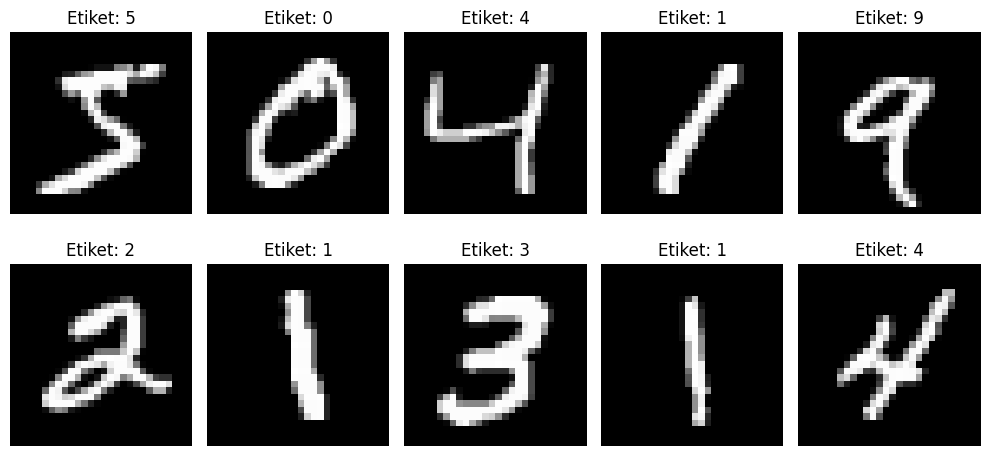

In [23]:
# Veri setinden örnek rakam görüntülerinin görselleştirilmesi

fig, axes = plt.subplots(2, 5, figsize=(10, 5))

for i, ax in enumerate(axes.flat):
    image, label = train_dataset[i]
    ax.imshow(image.squeeze(), cmap="gray")
    ax.set_title(f"Etiket: {label}")
    ax.axis("off")

plt.tight_layout()
plt.show()

In [24]:
# Eğitim veri setinin train ve validation olarak ayrılması

train_size = int(0.8 * len(train_dataset))
val_size = len(train_dataset) - train_size

train_dataset, val_dataset = random_split(
    train_dataset,
    [train_size, val_size]
)

print("Train veri sayısı      :", len(train_dataset))
print("Validation veri sayısı :", len(val_dataset))
print("Test veri sayısı       :", len(test_dataset))

Train veri sayısı      : 48000
Validation veri sayısı : 12000
Test veri sayısı       : 10000


In [25]:
# Veri kümelerinin batch'ler halinde modele aktarılması için DataLoader oluşturulması

batch_size = 64

train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=batch_size,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False
)

In [26]:
# Oluşturulan veri yükleyicilerinin kontrol edilmesi

print("Train batch sayısı      :", len(train_loader))
print("Validation batch sayısı :", len(val_loader))
print("Test batch sayısı       :", len(test_loader))

Train batch sayısı      : 750
Validation batch sayısı : 188
Test batch sayısı       : 157


# 3. Temel MLP Modelinin Oluşturulması

Bu bölümde MNIST veri seti için kullanılacak Multi-Layer Perceptron (MLP) modeli oluşturulacaktır. Ödev yönergelerine uygun olarak en az iki gizli katman (hidden layer) ve ReLU aktivasyon fonksiyonu kullanılacaktır.

In [27]:
# MLP modelinin oluşturulması
# Giriş katmanı: 784 nöron (28x28 görüntü)
# Gizli katmanlar: 256 ve 128 nöron
# Çıkış katmanı: 10 nöron (0-9 rakam sınıfları)
# Aktivasyon fonksiyonu: ReLU

class MLP(nn.Module):
    def __init__(self):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(28 * 28, 256),
            nn.ReLU(),

            nn.Linear(256, 128),
            nn.ReLU(),

            nn.Linear(128, 10)
        )

    def forward(self, x):
        # Görüntülerin düzleştirilmesi (28x28 -> 784)
        x = x.view(x.size(0), -1)
        return self.network(x)


In [28]:
# Modelin oluşturulması ve seçilen cihaza (GPU/CPU) aktarılması

model = MLP().to(device)

print(model)

MLP(
  (network): Sequential(
    (0): Linear(in_features=784, out_features=256, bias=True)
    (1): ReLU()
    (2): Linear(in_features=256, out_features=128, bias=True)
    (3): ReLU()
    (4): Linear(in_features=128, out_features=10, bias=True)
  )
)


In [29]:
# Çok sınıflı sınıflandırma problemi için kayıp fonksiyonunun tanımlanması

criterion = nn.CrossEntropyLoss()

In [30]:
# Model parametrelerini güncellemek için Adam optimizer'ının tanımlanması

optimizer = optim.Adam(
    model.parameters(),
    lr=0.001
)

In [31]:
# Modeldeki toplam eğitilebilir parametre sayısının hesaplanması

total_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

print("Toplam eğitilebilir parametre sayısı:", total_params)

Toplam eğitilebilir parametre sayısı: 235146


# 4. Modelin Eğitilmesi ve Değerlendirilmesi

Bu bölümde oluşturulan MLP modeli eğitilecek, eğitim süreci boyunca loss ve accuracy değerleri takip edilecek ve modelin performansı test veri kümesi üzerinde değerlendirilecektir.

In [32]:
# Eğitim sürecinde kullanılacak değişkenlerin oluşturulması

import time

num_epochs = 20

train_losses = []
val_losses = []

train_accuracies = []
val_accuracies = []

In [33]:
# Modelin eğitilmesi ve doğrulama sonuçlarının hesaplanması

start_time = time.time()

for epoch in range(num_epochs):

    # ---------------------
    # Eğitim Aşaması
    # ---------------------

    model.train()

    running_loss = 0
    correct = 0
    total = 0

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)

        loss = criterion(outputs, labels)

        loss.backward()

        optimizer.step()

        running_loss += loss.item()

        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)

        correct += (predicted == labels).sum().item()

    train_loss = running_loss / len(train_loader)
    train_acc = 100 * correct / total

    train_losses.append(train_loss)
    train_accuracies.append(train_acc)

    # ---------------------
    # Validation Aşaması
    # ---------------------

    model.eval()

    running_val_loss = 0
    correct = 0
    total = 0

    with torch.no_grad():

        for images, labels in val_loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)

            loss = criterion(outputs, labels)

            running_val_loss += loss.item()

            _, predicted = torch.max(outputs, 1)

            total += labels.size(0)

            correct += (predicted == labels).sum().item()

    val_loss = running_val_loss / len(val_loader)
    val_acc = 100 * correct / total

    val_losses.append(val_loss)
    val_accuracies.append(val_acc)

    print(
        f"Epoch [{epoch+1}/{num_epochs}] | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.2f}% | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.2f}%"
    )

training_time = time.time() - start_time

Epoch [1/20] | Train Loss: 0.3166 | Train Acc: 90.93% | Val Loss: 0.1646 | Val Acc: 95.21%
Epoch [2/20] | Train Loss: 0.1236 | Train Acc: 96.26% | Val Loss: 0.1235 | Val Acc: 96.36%
Epoch [3/20] | Train Loss: 0.0808 | Train Acc: 97.53% | Val Loss: 0.0981 | Val Acc: 96.98%
Epoch [4/20] | Train Loss: 0.0578 | Train Acc: 98.22% | Val Loss: 0.1046 | Val Acc: 96.80%
Epoch [5/20] | Train Loss: 0.0425 | Train Acc: 98.64% | Val Loss: 0.0901 | Val Acc: 97.31%
Epoch [6/20] | Train Loss: 0.0325 | Train Acc: 99.00% | Val Loss: 0.0841 | Val Acc: 97.54%
Epoch [7/20] | Train Loss: 0.0265 | Train Acc: 99.12% | Val Loss: 0.0822 | Val Acc: 97.62%
Epoch [8/20] | Train Loss: 0.0204 | Train Acc: 99.36% | Val Loss: 0.0898 | Val Acc: 97.48%
Epoch [9/20] | Train Loss: 0.0193 | Train Acc: 99.34% | Val Loss: 0.0960 | Val Acc: 97.64%
Epoch [10/20] | Train Loss: 0.0143 | Train Acc: 99.53% | Val Loss: 0.1001 | Val Acc: 97.62%
Epoch [11/20] | Train Loss: 0.0142 | Train Acc: 99.53% | Val Loss: 0.0969 | Val Acc: 97.8

In [34]:
# Toplam eğitim süresinin hesaplanması

print(f"Toplam eğitim süresi: {training_time:.2f} saniye")

Toplam eğitim süresi: 147.54 saniye


In [35]:
# Test veri kümesi üzerinde model performansının ölçülmesi

model.eval()

correct = 0
total = 0

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)

        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)

        correct += (predicted == labels).sum().item()

test_accuracy = 100 * correct / total

print(f"Test Accuracy: {test_accuracy:.2f}%")

Test Accuracy: 97.87%


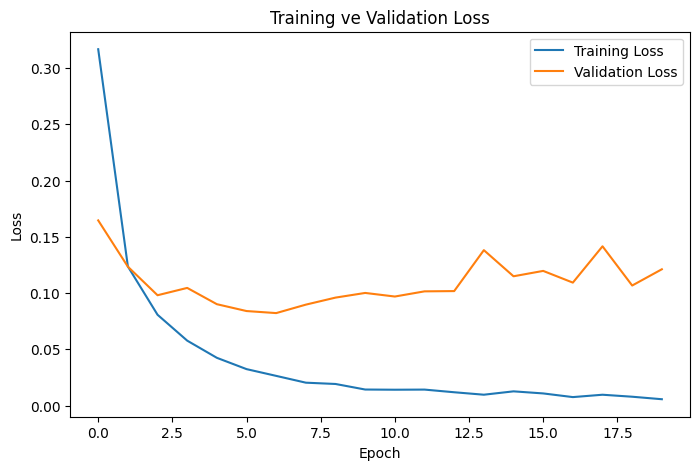

In [61]:
# Eğitim ve doğrulama loss değerlerinin görselleştirilmesi ve kaydedilmesi

plt.figure(figsize=(8, 5))

plt.plot(train_losses, label="Training Loss")
plt.plot(val_losses, label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training ve Validation Loss")
plt.legend()

plt.savefig("loss_graph.png", dpi=300, bbox_inches="tight")

plt.show()

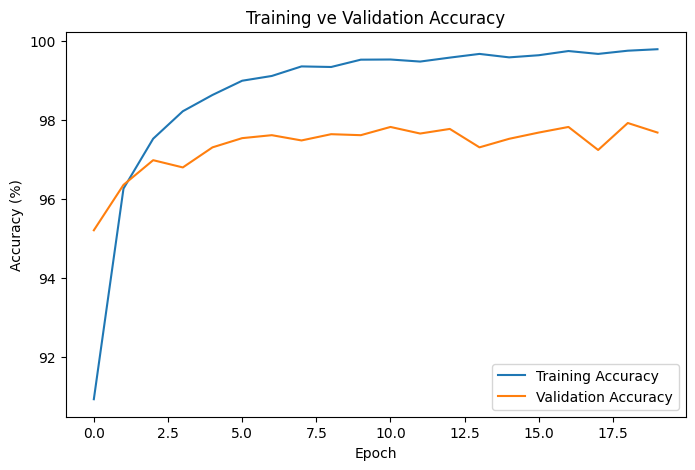

In [62]:
# Eğitim ve doğrulama accuracy değerlerinin görselleştirilmesi ve kaydedilmesi

plt.figure(figsize=(8, 5))

plt.plot(train_accuracies, label="Training Accuracy")
plt.plot(val_accuracies, label="Validation Accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("Training ve Validation Accuracy")
plt.legend()

plt.savefig("accuracy_graph.png", dpi=300, bbox_inches="tight")

plt.show()

In [38]:
# Nihai performans değerlerinin özetlenmesi

print("========== SONUÇLAR ==========")

print(f"Son Training Loss      : {train_losses[-1]:.4f}")
print(f"Son Validation Loss    : {val_losses[-1]:.4f}")

print(f"Son Training Accuracy  : {train_accuracies[-1]:.2f}%")
print(f"Son Validation Accuracy: {val_accuracies[-1]:.2f}%")

print(f"Test Accuracy          : {test_accuracy:.2f}%")

print(f"Eğitim Süresi          : {training_time:.2f} saniye")

========== SONUÇLAR ==========
Son Training Loss      : 0.0057
Son Validation Loss    : 0.1212
Son Training Accuracy  : 99.79%
Son Validation Accuracy: 97.68%
Test Accuracy          : 97.87%
Eğitim Süresi          : 147.54 saniye


# 5. Kendi El Yazısı Görüntülerinin Test Edilmesi

Bu bölümde kendi el yazımla oluşturduğum rakam görüntüleri MNIST formatına dönüştürülecek ve eğitilmiş MLP modeli kullanılarak tahmin işlemi gerçekleştirilecektir.

In [39]:
# Görüntü yükleme ve işleme işlemleri için gerekli kütüphanelerin içe aktarılması

from google.colab import files
from PIL import Image

import cv2
import numpy as np
import matplotlib.pyplot as plt


In [50]:
# Öğrenci numarasını içeren görüntünün Colab ortamına yüklenmesi

uploaded = files.upload()

Saving numara.jpeg to numara.jpeg


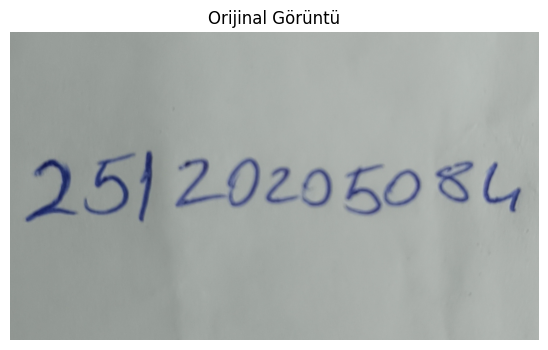

In [51]:
# Yüklenen görüntünün okunması ve görüntülenmesi

image_path = list(uploaded.keys())[0]

image = cv2.imread(image_path)

plt.figure(figsize=(10,4))
plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.title("Orijinal Görüntü")
plt.show()

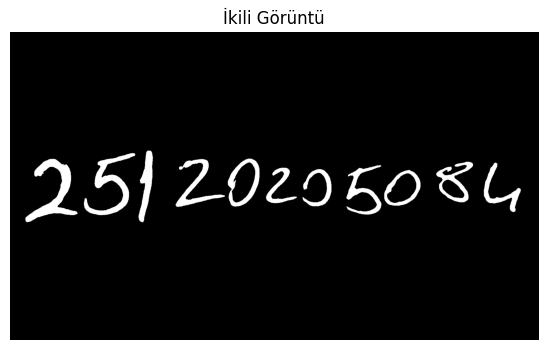

In [52]:
# Görüntünün gri tonlamaya dönüştürülmesi ve ikili görüntü oluşturulması

gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

_, thresh = cv2.threshold(
    gray,
    127,
    255,
    cv2.THRESH_BINARY_INV
)

plt.figure(figsize=(10,4))
plt.imshow(thresh, cmap="gray")
plt.axis("off")
plt.title("İkili Görüntü")
plt.show()

In [53]:
# Görüntü içerisindeki rakamların konumlarının belirlenmesi

contours, _ = cv2.findContours(
    thresh.copy(),
    cv2.RETR_EXTERNAL,
    cv2.CHAIN_APPROX_SIMPLE
)

bounding_boxes = []

for contour in contours:

    x, y, w, h = cv2.boundingRect(contour)

    if w > 5 and h > 5:
        bounding_boxes.append((x, y, w, h))

bounding_boxes = sorted(
    bounding_boxes,
    key=lambda box: box[0]
)

print("Bulunan rakam sayısı:", len(bounding_boxes))

Bulunan rakam sayısı: 11


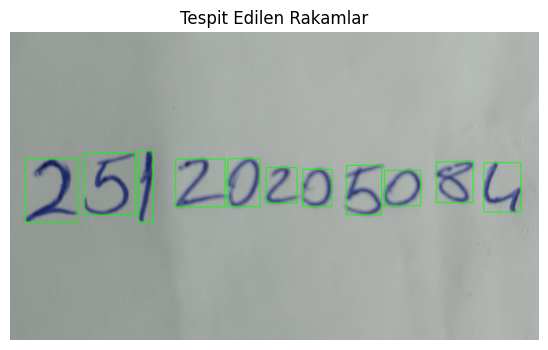

In [54]:
# Tespit edilen rakamların kutular ile gösterilmesi

image_boxes = image.copy()

for x, y, w, h in bounding_boxes:

    cv2.rectangle(
        image_boxes,
        (x, y),
        (x + w, y + h),
        (0, 255, 0),
        2
    )

plt.figure(figsize=(12,4))
plt.imshow(cv2.cvtColor(image_boxes, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.title("Tespit Edilen Rakamlar")
plt.show()

In [55]:
# Her rakamın ayrı ayrı kesilmesi ve 28x28 boyutuna dönüştürülmesi

digit_images = []

for x, y, w, h in bounding_boxes:

    digit = thresh[y:y+h, x:x+w]

    digit = cv2.resize(
        digit,
        (20, 20)
    )

    canvas = np.zeros((28, 28), dtype=np.uint8)

    canvas[4:24, 4:24] = digit

    digit_images.append(canvas)

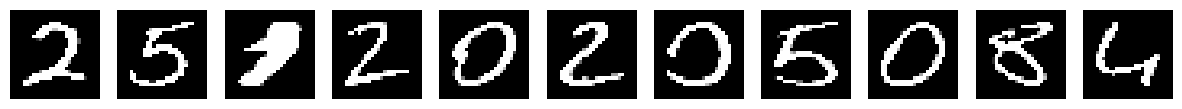

In [56]:
# Ayrılan rakamların görselleştirilmesi

plt.figure(figsize=(15,3))

for i, digit in enumerate(digit_images):

    plt.subplot(1, len(digit_images), i + 1)
    plt.imshow(digit, cmap="gray")
    plt.axis("off")

plt.show()

In [57]:
# Ayrılan rakamlar üzerinde tahmin yapılması

predictions = []

model.eval()

with torch.no_grad():

    for digit in digit_images:

        digit = digit.astype(np.float32) / 255.0

        tensor = torch.tensor(
            digit,
            dtype=torch.float32
        ).unsqueeze(0).unsqueeze(0)

        tensor = tensor.to(device)

        output = model(tensor)

        prediction = torch.argmax(
            output,
            dim=1
        ).item()

        predictions.append(str(prediction))

In [58]:
# Tahmin edilen öğrenci numarasının gösterilmesi

predicted_student_id = "".join(predictions)

print("Tahmin Edilen Numara:")
print(predicted_student_id)

Tahmin Edilen Numara:
25820205054


In [59]:
# Gerçek öğrenci numarası ile tahmin edilen sonucun karşılaştırılması

true_student_id = "25120205084"

print("Gerçek Numara :", true_student_id)
print("Tahmin Edilen :", predicted_student_id)

if true_student_id == predicted_student_id:
    print("Tüm rakamlar doğru tahmin edildi.")
else:
    print("Bazı rakamlar yanlış tahmin edildi.")

Gerçek Numara : 25120205084
Tahmin Edilen : 25820205054
Bazı rakamlar yanlış tahmin edildi.


In [60]:
# Eğitilen modelin kaydedilmesi

torch.save(model.state_dict(), "mlp_model.pth")

print("Model başarıyla kaydedildi.")

Model başarıyla kaydedildi.
